# Figure creator - AFM manuscript - Nidda Saaed

This notebook contains code to create a part of the figures shown in the AFM manuscript by first author Nidda Saaed, entitled

__"Electrically Enhanced Intraperitoneal Drug Delivery Resolved by Fluorescence Lifetime Imaging Microscopy"__


## Settings

__packages__

In [1]:
import os
import glob
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.cm as cm
from matplotlib import colors as mcolors
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from brokenaxes import brokenaxes
from matplotlib.ticker import LogLocator, LogFormatterMathtext, FixedLocator, NullLocator, FuncFormatter, NullFormatter

# download package below once, then comment out
# pip install brokenaxes

__settings for uniform figures__

In [2]:
# font
plt.rcParams['font.sans-serif'] = ['Arial']
plt.rcParams['font.family'] = 'sans-serif'

# fontsizes
SIZE_TITLE = 18
SIZE_YLABEL = 16
SIZE_XLABEL = 16
SIZE_TICKS = 14

# fontweights
WEIGHT_TITLE = "bold"
WEIGHT_XLABEL = "bold"
WEIGHT_YLABEL = "bold"
WEIGHT_TICKS = "bold"

# group colors
COLOR_LIST = [
    "royalblue",
    "firebrick",
    "mediumseagreen",
    "magenta"
    ]

## Figure 3

__input/output__

In [3]:
# read in datafile
DATA_DIR = r"S:\Exp_Heelkunde_digital_microscopy\Nidda Saeed\AFM Manuscript\Fig 3 Invitro"
DATA_FILE = r"human fixed samples data"
FILE_EXT = r".csv"
PATH_TO_FILE = os.path.join(DATA_DIR, DATA_FILE+FILE_EXT)

# define output directory to save figures
OUTPUT_DIR = os.path.join(DATA_DIR, "Figures")
os.makedirs(OUTPUT_DIR, exist_ok=True)

__reading data__

In [4]:
# read sheet
raw = pd.read_csv(PATH_TO_FILE, encoding="cp1252")

# reformat dilution data to exact concentrations
raw["Dilution"] = raw["Dilution"].str.replace(
    r"([^ ]+)\s*\(([\d.]+)\s*µg.*",
    r"\2 µg/mL (\1)",
    regex=True
)

# remove specific outlier for analysis - on request
raw = raw[
    ~(
        (raw["Dilution"] == "29.2 µg/mL (1:250)") &
        (raw["Treatment"] == "EMDA") &
        (raw["ROI"] == "ROI2") &
        np.isclose(raw["MFI"], 68.52731491)
    )
]

plot_df = raw.copy()

print(plot_df.groupby(["ROI", "Treatment"]).size())

ROI   Treatment
ROI1  EMDA         60
      PD           60
ROI2  EMDA         60
      PD           60
ROI3  EMDA         60
      PD           60
dtype: int64


__call dataframe__

In [5]:
plot_df

,Dilution,Treatment,ROI,MFI
0,73 µg/mL (1:100),PD,ROI1,62.483571
1,73 µg/mL (1:100),PD,ROI1,79.308678
2,73 µg/mL (1:100),PD,ROI1,63.238443
3,73 µg/mL (1:100),PD,ROI1,67.615149
4,73 µg/mL (1:100),PD,ROI1,58.829233
...,...,...,...,...
355,14.6 µg/mL (1:500),EMDA,ROI3,14.974706
356,14.6 µg/mL (1:500),EMDA,ROI3,14.814869
357,14.6 µg/mL (1:500),EMDA,ROI3,12.113414
358,14.6 µg/mL (1:500),EMDA,ROI3,18.227186


__supporting functions__

In [6]:
def violin_width_at_y(violin, y):
    """
    Determine violin width at a given y-value.
    """

    verts = violin.get_paths()[0].vertices
    xs = []

    for (x1, y1), (x2, y2) in zip(verts[:-1], verts[1:]):

        if (y1 <= y <= y2) or (y2 <= y <= y1):

            if y1 != y2:
                x = x1 + (y - y1) * (x2 - x1) / (y2 - y1)
                xs.append(x)

    if len(xs) >= 2:
        return min(xs), max(xs)

    return None, None


def plot_roi_dilution(
    DF,
    group_names=("PD", "EMDA"),
    colors=COLOR_LIST[:2],
    ymax=None,
    save_dir=None
):

    # extract dilution
    dilutions = np.sort(DF.Dilution.unique())
    if len(dilutions) > 1:
        raise ValueError("More than 1 dilution in data which is supposed to have only 1 dilution to plot")
    else:
        dilution = DF.Dilution.unique()[0]



    # --------------------------------------------------
    # Plot
    # --------------------------------------------------

    sns.set_theme(style="ticks")

    fig, ax = plt.subplots(figsize=(6, 6))

    sns.violinplot(
        data=DF,
        x="ROI",
        y="MFI",
        hue="Treatment",
        palette=colors,
        inner=None,
        cut=0,
        linewidth=2,
        ax=ax,
        density_norm="width",
    )

    sns.stripplot(
        data=DF,
        x="ROI",
        y="MFI",
        hue="Treatment",
        dodge=True,
        jitter=False,
        marker="o",
        size=4,
        linewidth=1,
        edgecolor="auto",
        palette=["white", "white"],
        alpha=1,
        ax=ax,
        legend=False
    )

    # --------------------------------------------------
    # Make violins transparent
    # --------------------------------------------------

    n_violins = DF["ROI"].nunique() * len(group_names)

    violins = ax.collections[:n_violins]

    for violin in violins:

        fc = violin.get_facecolor()

        violin.set_facecolor("none")
        violin.set_edgecolor(fc)
        violin.set_linewidth(2)

    # --------------------------------------------------
    # Median & Quartiles
    # --------------------------------------------------

    k = 0

    for roi in DF["ROI"].unique():

        for treatment in group_names:

            vals = DF.loc[
                (DF["ROI"] == roi)
                & (DF["Treatment"] == treatment),
                "MFI"
            ]

            q25, med, q75 = np.percentile(
                vals,
                [25, 50, 75]
            )

            violin = violins[k]
            k += 1

            for stat, ls, frac, lw in [

                (q25, "--", 1.0, 1.2),
                (med, "-", 1.0, 2.2),
                (q75, "--", 1.0, 1.2)

            ]:

                xmin, xmax = violin_width_at_y(
                    violin,
                    stat
                )

                if xmin is None:
                    continue

                xc = (xmin + xmax) / 2
                halfwidth = frac * (xmax - xmin) / 2

                ax.hlines(
                    stat,
                    xc - halfwidth,
                    xc + halfwidth,
                    color="black",
                    lw=lw,
                    ls=ls,
                    zorder=20
                )

    # --------------------------------------------------
    # Styling
    # --------------------------------------------------

    if ymax is None:
        ymax = 1.05 * DF["MFI"].max()

    tick_step = 20

    ax.set_ylim(-20, ymax)
    ax.set_yticks(
        np.arange(
            0,
            ymax + tick_step,
            tick_step
        )
    )

    ax.set_title(
        f"{dilution}",
        fontsize=SIZE_TITLE,
        fontweight=WEIGHT_TITLE
    )

    ax.set_ylabel(
        "Mean intensity (a.u./area)",
        fontsize=SIZE_YLABEL,
        fontweight=WEIGHT_YLABEL
    )

    ax.set_xlabel(
        "Penetration depth",
        fontsize=SIZE_XLABEL,
        fontweight=WEIGHT_XLABEL
    )

    ax.tick_params(
        axis="both",
        which="major",
        direction="out",
        length=12,
        width=2,
        labelsize=14
    )

    for tick in ax.get_xticklabels():
        tick.set_fontsize(SIZE_TICKS)
        tick.set_fontweight(WEIGHT_TICKS)

    for tick in ax.get_yticklabels():
        tick.set_fontsize(SIZE_TICKS)
        tick.set_fontweight(WEIGHT_TICKS)

    for side in ["left", "bottom"]:

        ax.spines[side].set_visible(True)
        ax.spines[side].set_color("black")
        ax.spines[side].set_linewidth(2)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.grid(False)

    # --------------------------------------------------
    # Custom legend
    # --------------------------------------------------

    if ax.legend_ is not None:
        ax.legend_.remove()

    handles = [

        Patch(
            facecolor="white",
            edgecolor=colors[0],
            linewidth=2,
            label=group_names[0]
        ),

        Patch(
            facecolor="white",
            edgecolor=colors[1],
            linewidth=2,
            label=group_names[1]
        )
    ]

    ax.legend(
        handles=handles,
        frameon=False,
        title="Treatment"
    )

    ax.axhline(
    y=0,
    linestyle="dotted",
    color="black",
    alpha=0.3
    )


    plt.tight_layout()


    # Save figure
    if save_dir is not None:

        os.makedirs(save_dir, exist_ok=True)

        safe_name = (
            str(dilution)
            .replace("/", "_")
            .replace("\\", "_")
            .replace(":", "-")
            .replace(" ", "_")
        )

        outfile = os.path.join(
            save_dir,
            f"Fig_3 - {safe_name}.png"
        )

        fig.savefig(
            outfile,
            dpi=600,
            bbox_inches="tight",
            facecolor="white"
        )

        print(f"Saved: {outfile}")

    return fig, ax, DF

__visuals__

14.6 µg/mL (1:500)
Saved: S:\Exp_Heelkunde_digital_microscopy\Nidda Saeed\AFM Manuscript\Fig 3 Invitro\Figures\Fig_3 - 14.6_µg_mL_(1-500).png
29.2 µg/mL (1:250)
Saved: S:\Exp_Heelkunde_digital_microscopy\Nidda Saeed\AFM Manuscript\Fig 3 Invitro\Figures\Fig_3 - 29.2_µg_mL_(1-250).png
73 µg/mL (1:100)
Saved: S:\Exp_Heelkunde_digital_microscopy\Nidda Saeed\AFM Manuscript\Fig 3 Invitro\Figures\Fig_3 - 73_µg_mL_(1-100).png


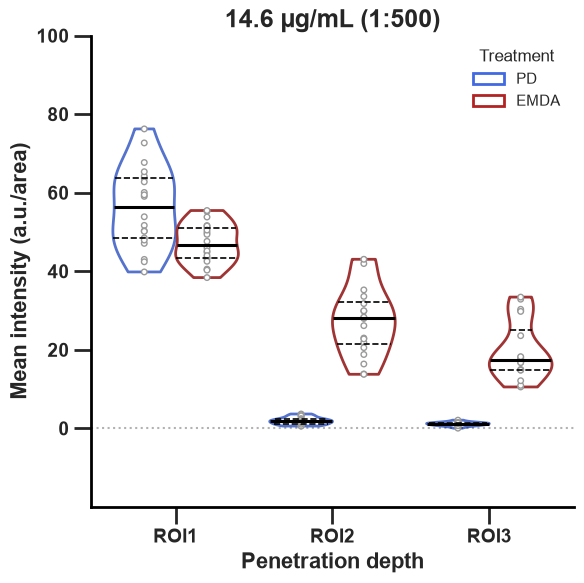

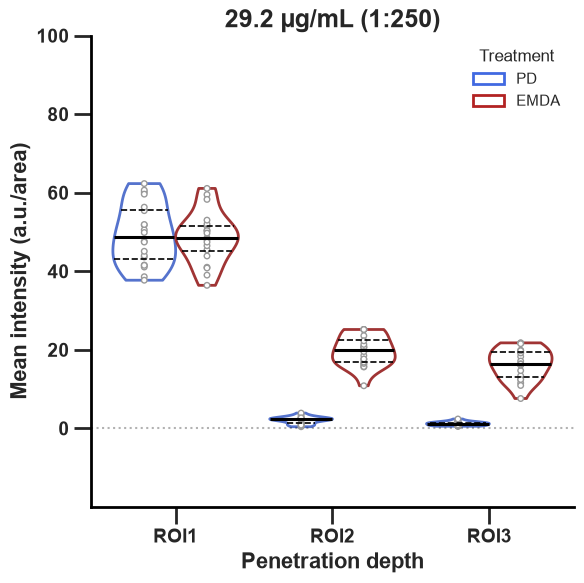

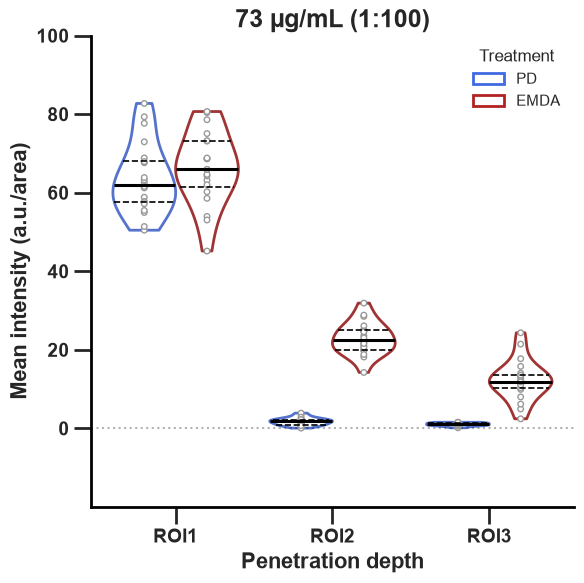

In [7]:
for dilution in np.sort(plot_df["Dilution"].unique()):
    print(dilution)
    df_sub = plot_df[plot_df["Dilution"] == dilution]

    fig, ax, _ = plot_roi_dilution(
        df_sub,
        ymax=100,
        save_dir=OUTPUT_DIR
    )

## Figure 4

__input/output__

In [8]:
# read in datafile
DATA_DIR = r"S:\Exp_Heelkunde_digital_microscopy\Nidda Saeed\AFM Manuscript\Fig 4 Invivo"
DATA_FILE = r"Invivo_MFI_data"
FILE_EXT = r".xlsx"
PATH_TO_FILE = os.path.join(DATA_DIR, DATA_FILE+FILE_EXT)

# define output directory to save figures
OUTPUT_DIR = os.path.join(DATA_DIR, "Figures")
os.makedirs(OUTPUT_DIR, exist_ok=True)

__reading data__

In [9]:
# read sheet
raw = pd.read_excel(PATH_TO_FILE, header=None)

# locate ROI rows
roi_rows = raw.index[raw.iloc[:, 0].astype(str).str.contains("ROI ", na=False)]

dfs = []

for roi_row in roi_rows:
    roi_name = str(raw.iloc[roi_row, 0])

    # values start in column 1
    values = pd.to_numeric(raw.iloc[roi_row, 1:].dropna(), errors="coerce").dropna()

    # first 24 = PD, next 24 = EMDA
    df_roi = pd.DataFrame({
        "ROI": roi_name,
        "Treatment": ["PD"] * 24 + ["EMDA"] * 24,
        "Value": values.iloc[:48].values
    })

    dfs.append(df_roi)

df = pd.concat(dfs, ignore_index=True)

# print(df.head())
# print(df.groupby(["ROI", "Treatment"]).size())

__call dataframe__

In [10]:
df

,ROI,Treatment,Value
0,ROI 1,PD,510.4
1,ROI 1,PD,426.6
2,ROI 1,PD,453.2
3,ROI 1,PD,463.7
4,ROI 1,PD,403.9
...,...,...,...
139,ROI 3,EMDA,119.8
140,ROI 3,EMDA,242.7
141,ROI 3,EMDA,137.6
142,ROI 3,EMDA,315.5


__supporting functions__

In [11]:
def violin_width_at_y(violin, y):
    """
    Determine violin width at a given y-value.
    """

    verts = violin.get_paths()[0].vertices
    xs = []

    for (x1, y1), (x2, y2) in zip(verts[:-1], verts[1:]):

        if (y1 <= y <= y2) or (y2 <= y <= y1):

            if y1 != y2:
                x = x1 + (y - y1) * (x2 - x1) / (y2 - y1)
                xs.append(x)

    if len(xs) >= 2:
        return min(xs), max(xs)

    return None, None


def plot_roi_sheet(
    raw,
    sheet_name="",
    group_names=("PD", "EMDA"),
    colors=COLOR_LIST[:2],
    ymax=None,
    save_dir=None
):

    # --------------------------------------------------
    # Build dataframe
    # --------------------------------------------------

    roi_rows = raw.index[
        raw.iloc[:, 0].astype(str).str.contains("ROI ", na=False)
    ]

    dfs = []

    for roi_row in roi_rows:

        roi_name = str(raw.iloc[roi_row, 0])

        values = (
            pd.to_numeric(
                raw.iloc[roi_row, 1:].dropna(),
                errors="coerce"
            )
            .dropna()
        )

        n_per_group = len(values) // 2

        df_roi = pd.DataFrame({
            "ROI": roi_name,
            "Treatment": (
                [group_names[0]] * n_per_group +
                [group_names[1]] * n_per_group
            ),
            "Value": values.values
        })

        dfs.append(df_roi)

    df = pd.concat(dfs, ignore_index=True)

    # --------------------------------------------------
    # Plot
    # --------------------------------------------------

    sns.set_theme(style="ticks")

    fig, ax = plt.subplots(figsize=(6, 6))

    sns.violinplot(
        data=df,
        x="ROI",
        y="Value",
        hue="Treatment",
        palette=colors,
        inner=None,
        cut=0,
        linewidth=2,
        ax=ax
    )

    sns.stripplot(
        data=df,
        x="ROI",
        y="Value",
        hue="Treatment",
        dodge=True,
        jitter=False,
        marker="o",
        size=4,
        linewidth=1,
        edgecolor="auto",
        palette=["white", "white"],
        alpha=1,
        ax=ax,
        legend=False
    )

    # --------------------------------------------------
    # Make violins transparent
    # --------------------------------------------------

    n_violins = df["ROI"].nunique() * len(group_names)

    violins = ax.collections[:n_violins]

    for violin in violins:

        fc = violin.get_facecolor()

        violin.set_facecolor("none")
        violin.set_edgecolor(fc)
        violin.set_linewidth(2)

    # --------------------------------------------------
    # Median & Quartiles
    # --------------------------------------------------

    k = 0

    for roi in df["ROI"].unique():

        for treatment in group_names:

            vals = df.loc[
                (df["ROI"] == roi)
                & (df["Treatment"] == treatment),
                "Value"
            ]

            q25, med, q75 = np.percentile(
                vals,
                [25, 50, 75]
            )

            violin = violins[k]
            k += 1

            for stat, ls, frac, lw in [

                (q25, "--", 1.0, 1.2),
                (med, "-", 1.0, 2.2),
                (q75, "--", 1.0, 1.2)

            ]:

                xmin, xmax = violin_width_at_y(
                    violin,
                    stat
                )

                if xmin is None:
                    continue

                xc = (xmin + xmax) / 2
                halfwidth = frac * (xmax - xmin) / 2

                ax.hlines(
                    stat,
                    xc - halfwidth,
                    xc + halfwidth,
                    color="black",
                    lw=lw,
                    ls=ls,
                    zorder=20
                )

    # --------------------------------------------------
    # Styling
    # --------------------------------------------------

    if ymax is None:
        ymax = 1.05 * df["Value"].max()

    tick_step = int(np.ceil(ymax / 4 / 50) * 50)

    ax.set_ylim(0, ymax)
    ax.set_yticks(
        np.arange(
            0,
            ymax + tick_step,
            tick_step
        )
    )

    ax.set_ylabel(
        "Mean intensity (a.u./area)",
        fontsize=SIZE_YLABEL,
        fontweight=WEIGHT_YLABEL
    )

    ax.set_xlabel(
        "Penetration depth",
        fontsize=SIZE_XLABEL,
        fontweight=WEIGHT_XLABEL
    )

    ax.tick_params(
        axis="both",
        which="major",
        direction="out",
        length=12,
        width=2,
        labelsize=14
    )

    for tick in ax.get_xticklabels():
        tick.set_fontsize(SIZE_TICKS)
        tick.set_fontweight(WEIGHT_TICKS)

    for tick in ax.get_yticklabels():
        tick.set_fontsize(SIZE_TICKS)
        tick.set_fontweight(WEIGHT_TICKS)

    for side in ["left", "bottom"]:

        ax.spines[side].set_visible(True)
        ax.spines[side].set_color("black")
        ax.spines[side].set_linewidth(2)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.grid(False)

    # --------------------------------------------------
    # Custom legend
    # --------------------------------------------------

    if ax.legend_ is not None:
        ax.legend_.remove()

    handles = [

        Patch(
            facecolor="white",
            edgecolor=colors[0],
            linewidth=2,
            label=group_names[0]
        ),

        Patch(
            facecolor="white",
            edgecolor=colors[1],
            linewidth=2,
            label=group_names[1]
        )
    ]

    ax.legend(
        handles=handles,
        frameon=False,
        title="Treatment"
    )

    # if sheet_name:
    #     ax.set_title(
    #         sheet_name,
    #         fontsize=SIZE_TITLE,
    #         fontweight=WEIGHT_TITLE
    #     )

    plt.tight_layout()


    # Save figure
    if save_dir is not None:

        os.makedirs(save_dir, exist_ok=True)

        safe_name = (
            str(sheet_name)
            .replace("/", "_")
            .replace("\\", "_")
            .replace(" ", "_")
        )

        outfile = os.path.join(
            save_dir,
            f"{safe_name}_violinplot.png"
        )

        fig.savefig(
            outfile,
            dpi=600,
            bbox_inches="tight",
            facecolor="white"
        )

        print(f"Saved: {outfile}")

    return fig, ax, df

__visuals__

Saved: S:\Exp_Heelkunde_digital_microscopy\Nidda Saeed\AFM Manuscript\Fig 4 Invivo\Figures\PD-RF_EMDA_violinplot.png


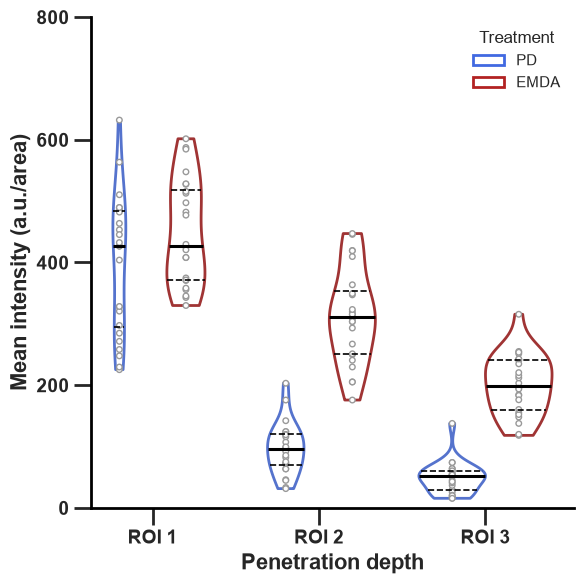

Saved: S:\Exp_Heelkunde_digital_microscopy\Nidda Saeed\AFM Manuscript\Fig 4 Invivo\Figures\PD-LF_EMDA_violinplot.png


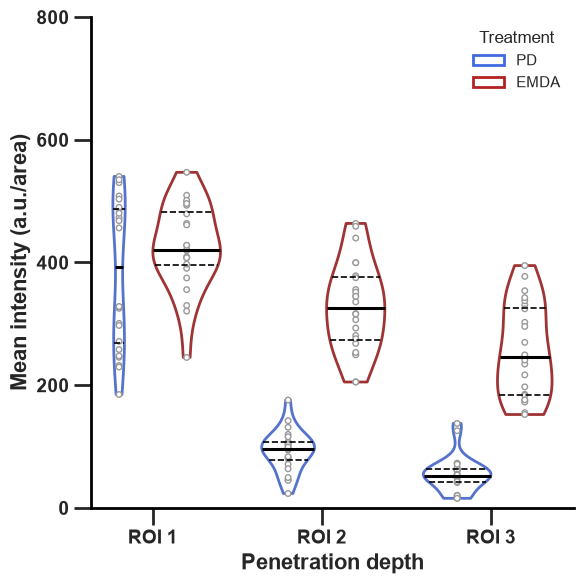

In [12]:
xls = pd.ExcelFile(PATH_TO_FILE)

for sheet in xls.sheet_names:

    raw = pd.read_excel(
        PATH_TO_FILE,
        sheet_name=sheet,
        header=None
    )

    fig, ax, df = plot_roi_sheet(
        raw,
        sheet_name=sheet,
        ymax=800,
        save_dir=OUTPUT_DIR
    )

    plt.show(fig)

## Figure 5

__input/output__

In [13]:
# read in datafile
DATA_DIR = r"S:\Exp_Heelkunde_digital_microscopy\Nidda Saeed\AFM Manuscript\Fig 5 cell study"
DATA_FILE = r"03_MANUSCRIPT_TABLE"
FILE_EXT = r".xlsx"
PATH_TO_FILE = os.path.join(DATA_DIR, DATA_FILE+FILE_EXT)

# define output directory to save figures
OUTPUT_DIR = os.path.join(DATA_DIR, "Figures")
os.makedirs(OUTPUT_DIR, exist_ok=True)

__reading data + call dataframe__

In [14]:
manuscript_table = pd.read_excel(PATH_TO_FILE)
manuscript_table

,Group,Concentration,Timepoint,N samples,Mean Intensity,Intensity SD,Tau Phase lifetime,Tau Phase SD
0,DOX NPs,2 µM,1,13,18.863798,3.683955,1.682985,0.368807
1,DOX NPs,2 µM,5,16,29.835645,10.612264,1.335648,0.325939
2,DOX NPs,2 µM,24,7,102.189156,17.202753,1.098639,0.149477
3,DOX NPs,20 µM,1,24,68.447483,37.150162,1.607490,0.315132
4,DOX NPs,20 µM,5,20,112.193955,67.862938,1.202101,0.262119
5,DOX NPs,20 µM,24,8,137.450851,42.229251,0.939232,0.149932
6,Free DOX,2 µM,1,9,31.879979,11.003819,1.529678,0.059437
7,Free DOX,2 µM,5,5,57.518567,5.256363,1.143302,0.159500
8,Free DOX,2 µM,24,7,119.001524,21.927275,0.968976,0.087333
9,Free DOX,20 µM,1,14,93.169879,42.331073,1.480935,0.078039


__supporting functions__

In [15]:
def plot_manuscript(MANUSCRIPT, GROUPS_TO_PLOT):

    # --------------------------------------------------------------
    # Filter requested groups
    # --------------------------------------------------------------
    df = MANUSCRIPT[MANUSCRIPT["Group"].isin(GROUPS_TO_PLOT)].copy()

    # Create setup label
    df["Setup"] = (
        df["Group"].astype(str)
        + " | "
        + df["Concentration"].astype(str)
    )

    # Order of plotting
    timepoints = sorted(df["Timepoint"].unique())
    setups = sorted(df["Setup"].unique())

    n_timepoints = len(timepoints)
    n_setups = len(setups)

    # --------------------------------------------------------------
    # Colors
    # --------------------------------------------------------------
    color_list = COLOR_LIST

    colors = {
        setup: color_list[i % len(color_list)]
        for i, setup in enumerate(setups)
    }


    # --------------------------------------------------------------
    # Markers
    # --------------------------------------------------------------

    marker_list = [
        "o",   # circle
        "s",   # square
        "^",   # triangle
        "D"    # diamond
    ]

    markers = {
        setup: marker_list[i % len(marker_list)]
        for i, setup in enumerate(setups)
    }

    # --------------------------------------------------------------
    # Figure
    # --------------------------------------------------------------
    fig, axes = plt.subplots(
        1,
        2,
        figsize=(14, 6),
        sharex=True
    )

    plot_info = [
        (
            "Mean Intensity",
            "Intensity SD",
            "Mean intensity per administration method",
            "Mean intensity (a.u./area)"
        ),
        (
            "Tau Phase lifetime",
            "Tau Phase SD",
            "Mean lifetime per administration method",
            "Mean lifetime [ns]"
        )
    ]

    x = np.array(timepoints)            # use real time values on x-axis

    for ax, (mean_col, std_col, title, ylabel) in zip(axes, plot_info):

        for s_idx, setup in enumerate(setups):

            # select data per setup
            df_selection = df[df['Setup'] == setup]
            means = df_selection[mean_col].values
            stds = df_selection[std_col].values

            # --- if you want connected points with error bars --- #
            ax.errorbar(
                x,
                means,
                yerr=stds,
                fmt=markers[setup],
                linewidth=1.5,
                markersize=8,
                color=colors[setup],
                markerfacecolor=colors[setup],
                markeredgecolor="black",
                markeredgewidth=1,
                capsize=4,
                linestyle='-',
                label=setup
            )
            # ---------------------------------------------------- #

            # debugging: add value to point
            # print(f'Setup: {setup}, Column: {mean_col}; \n  Means: {means}')


        # ax.set_title(
        #     title,
        #     fontsize=SIZE_TITLE,
        #     fontweight=WEIGHT_TITLE
        # )

        ax.set_ylabel(
            ylabel,
            fontsize=SIZE_YLABEL,
            fontweight=WEIGHT_YLABEL
        )

        ax.set_xlabel(
            "Incubation time [hrs]",
            fontsize=SIZE_XLABEL,
            fontweight=WEIGHT_XLABEL
        )

        # if x plotted with real range
        ax.set_xticks(
            timepoints
        )

        for tick in ax.get_xticklabels():
            tick.set_fontsize(SIZE_TICKS)
            tick.set_fontweight(WEIGHT_TICKS)

        for tick in ax.get_yticklabels():
            tick.set_fontsize(SIZE_TICKS)
            tick.set_fontweight(WEIGHT_TICKS)

        ax.set_xlim(min(timepoints)-1, max(timepoints)+1)

        ax.grid(False)
        ax.grid(
            axis="y",
            linestyle="--",
            alpha=0.4
        )

    # --------------------------------------------------------------
    # Shared legend
    # --------------------------------------------------------------
    handles = [
        Line2D(
            [0],
            [0],
            marker=markers[s],
            color="none",
            markerfacecolor=colors[s],
            markeredgecolor="black",
            markersize=8,
            linestyle="None",
            label=s
        )
        for s in setups
    ]

    fig.legend(
        handles=handles,
        title="Setup",
        bbox_to_anchor=(1.02, 0.98),
        loc="upper left",
        frameon=False
    )

    fig.tight_layout()

    return fig, axes

__visuals__

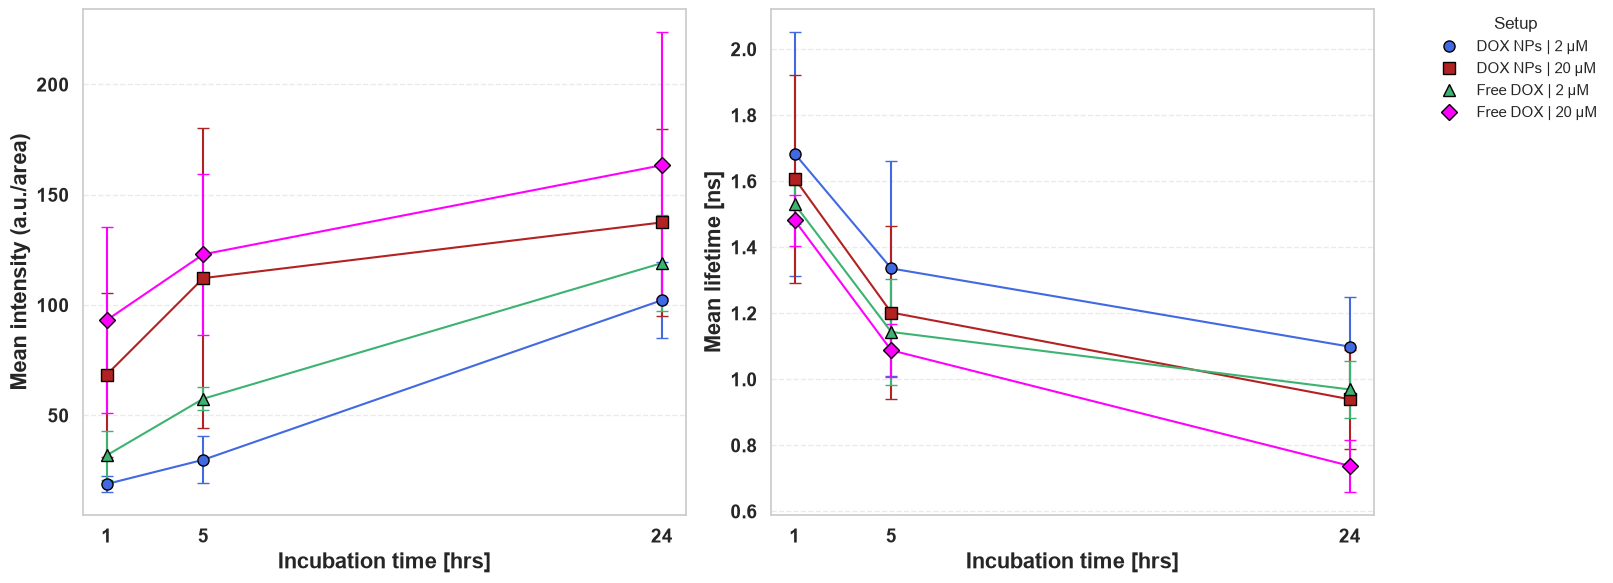

In [16]:
# specify groups to plot
groups_to_plot = [
    "DOX NPs",
    "Free DOX"
    #,"AZA-only"
]

fig, axes = plot_manuscript(MANUSCRIPT=manuscript_table, GROUPS_TO_PLOT=groups_to_plot)

outfile = os.path.join(
            OUTPUT_DIR,
            f"Fig_5 - Cell_study.png"
        )

fig.savefig(
            outfile,
            dpi=600,
            bbox_inches="tight",
            facecolor="white"
        )

plt.show()

## Figure 6

__define data__

In [17]:
# define retrieved data per group and tissue of origin
data = {
    'Tissue': [
        'Mesentery',
        'Liver',
        'Kidney',
        'Right Peritoneum',
        'Left Peritoneum',
        'Omentum',
        'Spleen',
        'Stomach',
        'All Tumors'
    ] * 3,

    'Group': (
        ['PD Dox NPs 6hr'] * 9 +
        ['EMDA DOX NPs 6hr'] * 9 +
        ['EMDA DOX NPs 24hr'] * 9
    ),

    'Mean': [
        # PD Dox NPs 6 hr
        936e6,
        632e6,
        0.425e6,
        672e6,
        974e6,
        6040e6,
        193e6,
        801e6,
        4070e6,

        # EMDA DOX NPs 6 hr
        1850e6,
        2020e6,
        0.425e6,
        8590e6,
        6040e6,
        57000e6,
        2940e6,
        2140e6,
        21090e6,

        # EMDA DOX NPs 24 hr
        1910e6,
        2330e6,
        0.425e6,
        801e6,
        784e6,
        29600e6,
        693e6,
        8590e6,
        8120e6
    ],

    'SD': [
        # PD Dox NPs 6 hr
        280e6,
        190e6,
        0.13e6,
        200e6,
        290e6,
        1800e6,
        58e6,
        240e6,
        1220e6,

        # EMDA DOX NPs 6 hr
        650e6,
        710e6,
        0.13e6,
        3000e6,
        2100e6,
        20000e6,
        1030e6,
        750e6,
        7400e6,

        # EMDA DOX NPs 24 hr
        670e6,
        820e6,
        0.13e6,
        280e6,
        275e6,
        10400e6,
        240e6,
        3000e6,
        2840e6
    ]
}

df = pd.DataFrame(data)

__figure settings__

In [18]:
# ============================================================
# GROUPS
# ============================================================

groups = [
    'PD Dox NPs 6hr',
    'EMDA DOX NPs 6hr',
    'EMDA DOX NPs 24hr'
]

group_labels = {
    'PD Dox NPs 6hr': 'PD 6 h',
    'EMDA DOX NPs 6hr': 'EMDA 6 h',
    'EMDA DOX NPs 24hr': 'EMDA 24 h'
}

colors = {
    'PD Dox NPs 6hr': '#3498db',
    'EMDA DOX NPs 6hr': '#e74c3c',
    'EMDA DOX NPs 24hr': '#2ecc71'
}


# ============================================================
# TISSUE GROUPS
# ============================================================

tumor_associated = [
    'Omentum',
    'All Tumors'
]

other_organs = [
    'Mesentery',
    'Liver',
    'Kidney',
    'Right Peritoneum',
    'Left Peritoneum',
    'Spleen',
    'Stomach'
]


# ============================================================
# SCALE TO ×10^9
# ============================================================

df['Mean_plot'] = df['Mean'] / 1e9
df['SD_plot'] = df['SD'] / 1e9


# ============================================================
# STYLE
# ============================================================

plt.rcParams.update({
    'font.family': 'Arial',
    'font.size': 12,
    'axes.labelsize': 14,
    'axes.titlesize': 14,
    'xtick.labelsize': 11,
    'ytick.labelsize': 12,
    'legend.fontsize': 11,
    'axes.linewidth': 1.2,
    'pdf.fonttype': 42,
    'ps.fonttype': 42
})

__visuals__

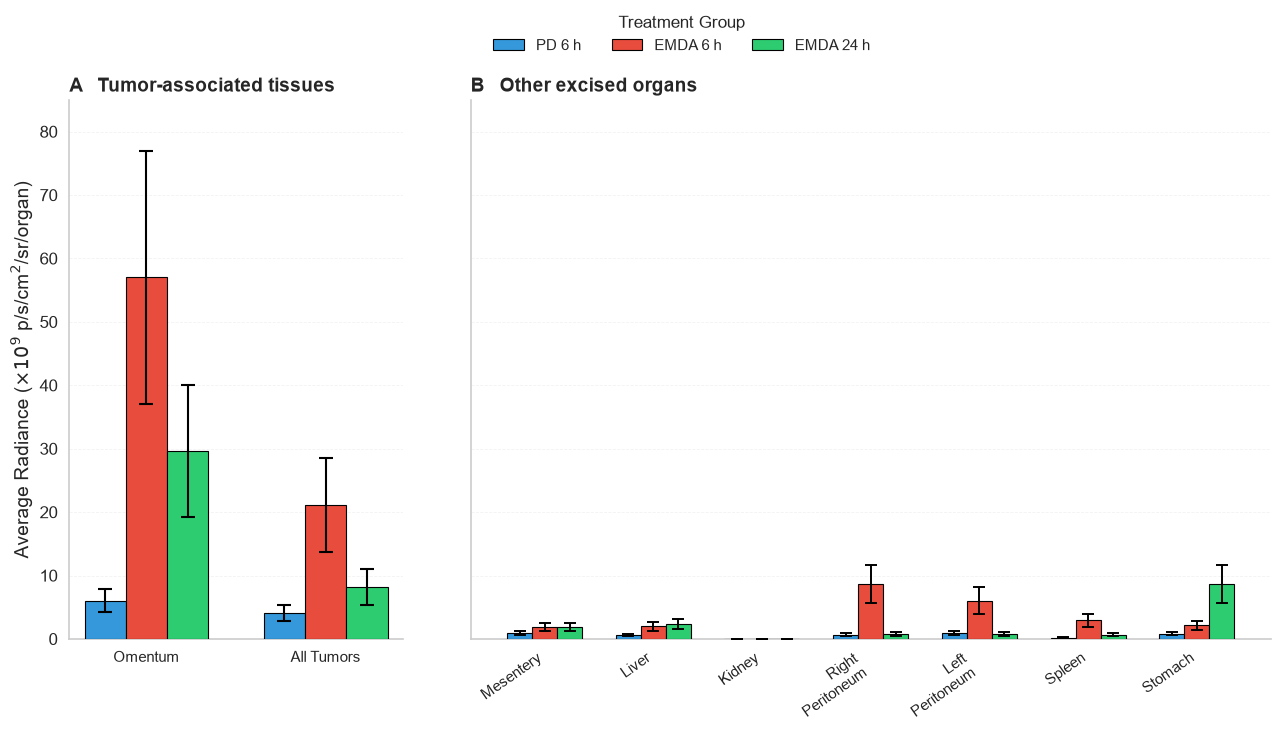

Figure saved successfully!


In [20]:
# ============================================================
# FIGURE
# ============================================================

fig, (ax1, ax2) = plt.subplots(
    1,
    2,
    figsize=(15.5, 7),
    sharey=True,
    gridspec_kw={
        'width_ratios': [1.0, 2.4],
        'wspace': 0.12
    }
)

bar_width = 0.23

Y_MAX = 85


# ============================================================
# PANEL A — TUMOR-ASSOCIATED TISSUES
# ============================================================

x1 = np.arange(len(tumor_associated))

for i, group in enumerate(groups):

    subset = (
        df[
            (df['Group'] == group) &
            (df['Tissue'].isin(tumor_associated))
        ]
        .set_index('Tissue')
        .reindex(tumor_associated)
    )

    positions = x1 + (i - 1) * bar_width

    ax1.bar(
        positions,
        subset['Mean_plot'],
        width=bar_width,
        yerr=subset['SD_plot'],
        capsize=5,
        color=colors[group],
        edgecolor='black',
        linewidth=0.8,
        label=group_labels[group],
        error_kw={
            'elinewidth': 1.5,
            'capthick': 1.5,
            'ecolor': 'black'
        },
        zorder=3
    )


ax1.set_xticks(x1)
ax1.set_xticklabels([
    'Omentum',
    'All Tumors'
])

ax1.set_ylabel(
    r'Average Radiance ($\times10^{9}$ p/s/cm$^{2}$/sr/organ)'
)

ax1.set_title(
    'A   Tumor-associated tissues',
    loc='left',
    fontweight='bold'
)

ax1.set_ylim(0, Y_MAX)


# ============================================================
# PANEL B — OTHER EXCISED ORGANS
# ============================================================

x2 = np.arange(len(other_organs))

for i, group in enumerate(groups):

    subset = (
        df[
            (df['Group'] == group) &
            (df['Tissue'].isin(other_organs))
        ]
        .set_index('Tissue')
        .reindex(other_organs)
    )

    positions = x2 + (i - 1) * bar_width

    ax2.bar(
        positions,
        subset['Mean_plot'],
        width=bar_width,
        yerr=subset['SD_plot'],
        capsize=4,
        color=colors[group],
        edgecolor='black',
        linewidth=0.8,
        label=group_labels[group],
        error_kw={
            'elinewidth': 1.4,
            'capthick': 1.4,
            'ecolor': 'black'
        },
        zorder=3
    )


ax2.set_xticks(x2)

ax2.set_xticklabels(
    [
        'Mesentery',
        'Liver',
        'Kidney',
        'Right\nPeritoneum',
        'Left\nPeritoneum',
        'Spleen',
        'Stomach'
    ],
    rotation=35,
    ha='right'
)

ax2.set_title(
    'B   Other excised organs',
    loc='left',
    fontweight='bold'
)

ax2.set_ylim(0, Y_MAX)


# ============================================================
# COMMON AXIS STYLE
# ============================================================

for ax in [ax1, ax2]:

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    ax.tick_params(
        axis='both',
        direction='out',
        width=1.2,
        length=5
    )

    ax.yaxis.grid(
        True,
        linestyle='--',
        linewidth=0.6,
        alpha=0.25,
        zorder=0
    )

    ax.xaxis.grid(False)


# ============================================================
# LEGEND
# ============================================================

handles, labels = ax1.get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    title='Treatment Group',
    frameon=False,
    loc='upper center',
    bbox_to_anchor=(0.52, 1.02),
    ncol=3
)


# ============================================================
# SAVE
# ============================================================

# plt.tight_layout(
#     rect=[0, 0, 1, 0.92]
# )

plt.savefig(
    'Fig7_IVIS_biodistribution_two_panels.png',
    dpi=600,
    bbox_inches='tight'
)

plt.savefig(
    'Fig7_IVIS_biodistribution_two_panels.pdf',
    bbox_inches='tight'
)

plt.show()

print("Figure saved successfully!")